# Banknote Authentication — kNN Modeling

This notebook prepares the dataset for machine learning, implements a k-Nearest Neighbors classifier from scratch, selects the hyperparameter `k`, and evaluates the final model.

The modeling workflow consists of:
- separating features and target,
- splitting the data into training, validation, and test sets,
- standardizing numerical features,
- implementing kNN from scratch,
- selecting the best value of `k`,
- evaluating the final classifier.

In [1]:
from pathlib import Path
import random

import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent


In [2]:
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "raw" / "data_banknote_authentication.txt"
print(data_path)


/Users/oliversulej/Desktop/github_projects/banknote-authentication-from-scratch/data/raw/data_banknote_authentication.txt


## Preparing Features and Target

Before building the classifier, we separate the input features from the target variable.

The feature matrix `X` contains the four numerical attributes used by the model, while the target vector `y` contains the class labels that we want to predict.

In [3]:
column_names = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

df = pd.read_csv(data_path, names=column_names)

In [4]:
features_names = ["variance", "skewness", "curtosis", "entropy"]

X = df[features_names]
y = df["class"]

## Train, Validation, and Test Split

Before training the classifier, the dataset must be divided into three independent subsets:

- **Training set** — used by the model to learn from known observations.
- **Validation set** — used to compare different values of the hyperparameter `k` and select the best configuration.
- **Test set** — used only once at the end to estimate how well the final model generalizes to previously unseen data.

To preserve the original class proportions in each subset, we will perform a **stratified split**, meaning that observations from class 0 and class 1 will be divided separately and then combined.

### Separating Class Indices

To create a stratified split manually, we first collect the row indices belonging to each target class.  
These indices will later be shuffled and divided into training, validation, and test subsets.

In [5]:
class_0_indices = df[df["class"]==0].index.to_list()
class_1_indices = df[df["class"]==1].index.to_list()

print(len(class_0_indices))
print(len(class_1_indices))

762
610


### Shuffling Class Indices

Before splitting the observations into training, validation, and test sets, the indices of each class are shuffled independently.

A fixed random seed is used to make the split reproducible, meaning that the same observations will be assigned to the same subsets every time the notebook is run.

In [6]:
rng = random.Random(42)

rng.shuffle(class_0_indices)
rng.shuffle(class_1_indices)



### Splitting Each Class

Each target class is divided separately into training, validation, and test subsets.

We use approximately:
- **70%** of observations for training,
- **15%** for validation,
- **15%** for final testing.

Splitting each class separately preserves a similar class distribution in all three subsets.

In [7]:
class_0_train_size = int(0.7*len(class_0_indices))
class_0_validation_size = int(0.15*len(class_0_indices))

class_1_train_size = int(0.7*len(class_1_indices))
class_1_validation_size = int(0.15*len(class_1_indices))

print(f"Class 0 training set size: {class_0_train_size}")
print(f"Class 0 validation set size: {class_0_validation_size}")
print(f"Class 1 training set size: {class_1_train_size}")
print(f"Class 1 validation set size: {class_1_validation_size}")

Class 0 training set size: 533
Class 0 validation set size: 114
Class 1 training set size: 427
Class 1 validation set size: 91


### Creating Train, Validation, and Test Indices

Using the shuffled class-specific indices, we now create separate training, validation, and test index lists.

The split is performed independently for each class and the resulting parts are then combined. This keeps the class proportions approximately consistent across all three subsets.

In [8]:
class_0_train_indices = class_0_indices[:class_0_train_size]
class_0_validation_indices = class_0_indices[class_0_train_size:class_0_train_size+class_0_validation_size]
class_0_test_indices = class_0_indices[class_0_train_size+class_0_validation_size:]

class_1_train_indices = class_1_indices[:class_1_train_size]
class_1_validation_indices = class_1_indices[class_1_train_size:class_1_train_size+class_1_validation_size]
class_1_test_indices = class_1_indices[class_1_train_size+class_1_validation_size:]

train_indices = class_0_train_indices + class_1_train_indices
validation_indices = class_0_validation_indices + class_1_validation_indices
test_indices = class_0_test_indices + class_1_test_indices

rng.shuffle(train_indices)
rng.shuffle(validation_indices)
rng.shuffle(test_indices)

print(len(train_indices))
print(len(validation_indices))
print(len(test_indices))

960
205
207


### Creating Training, Validation, and Test Sets

Using the previously created index lists, we now extract the corresponding feature rows and target labels.

This creates six separate objects:

- `X_train`, `y_train`
- `X_validation`, `y_validation`
- `X_test`, `y_test`

The feature matrices contain the input variables, while the target vectors contain the corresponding class labels.

In [9]:
X_train = X.loc[train_indices]
y_train = y.loc[train_indices]

X_validation = X.loc[validation_indices]
y_validation = y.loc[validation_indices]

X_test = X.loc[test_indices]
y_test = y.loc[test_indices]

### Split Verification

We verify the dimensions of each subset and check whether the class proportions remain similar after the stratified split.

In [10]:
print("Training:")
print(X_train.shape, y_train.shape)

print("\nValidation:")
print(X_validation.shape, y_validation.shape)

print("\nTest:")
print(X_test.shape, y_test.shape)

Training:
(960, 4) (960,)

Validation:
(205, 4) (205,)

Test:
(207, 4) (207,)


In [11]:
print("Training class proportions:")
print(y_train.value_counts(normalize=True))

print("\nValidation class proportions:")
print(y_validation.value_counts(normalize=True))

print("\nTest class proportions:")
print(y_test.value_counts(normalize=True))

Training class proportions:
class
0    0.555208
1    0.444792
Name: proportion, dtype: float64

Validation class proportions:
class
0    0.556098
1    0.443902
Name: proportion, dtype: float64

Test class proportions:
class
0    0.555556
1    0.444444
Name: proportion, dtype: float64


## Feature Standardization

k-Nearest Neighbors is a distance-based algorithm, so features with larger numerical scales can have a disproportionately large influence on the calculated distances.

To make the features comparable, we standardize each numerical feature using:

$$
z = \frac{x - \mu}{\sigma}
$$

where:

- $x$ is the original feature value,
- $\mu$ is the mean of the feature,
- $\sigma$ is the standard deviation of the feature.

The mean and standard deviation are calculated **only from the training set** to avoid data leakage. The same training statistics are then used to transform the validation and test sets.

In [12]:
train_means = X_train.mean()
train_stds = X_train.std()

print(train_means)
print(train_stds)

variance    0.416640
skewness    1.927704
curtosis    1.420738
entropy    -1.226519
dtype: float64
variance    2.831325
skewness    5.893777
curtosis    4.333197
entropy     2.098062
dtype: float64


In [13]:
X_train_scaled = (X_train - train_means) / train_stds

X_validation_scaled = (X_validation - train_means) / train_stds

X_test_scaled = (X_test - train_means) / train_stds

### Standardization Verification

After standardizing the features, we verify that the training features have approximately zero mean and unit standard deviation.

Only the training set is expected to satisfy these properties exactly, because the validation and test sets were transformed using statistics calculated from the training data.

In [14]:
print("Scaled training means:")
print(X_train_scaled.mean())

print("\nScaled training standard deviations:")
print(X_train_scaled.std())

Scaled training means:
variance   -1.850372e-18
skewness   -2.405483e-17
curtosis   -1.202742e-17
entropy    -9.251859e-18
dtype: float64

Scaled training standard deviations:
variance    1.0
skewness    1.0
curtosis    1.0
entropy     1.0
dtype: float64


## k-Nearest Neighbors from Scratch

We now implement the k-Nearest Neighbors (kNN) classifier without using a machine learning library.

For a new observation, the algorithm:

1. calculates its distance to every observation in the training set,
2. selects the `k` nearest neighbors,
3. checks their class labels,
4. predicts the class that appears most frequently among the neighbors.

Because the features have been standardized, each feature contributes on a more comparable scale to the distance calculation.

### Squared Euclidean Distance

kNN requires a distance measure to compare observations.  
We use the squared Euclidean distance because taking the square root would not change the ordering of the nearest neighbors.

In [15]:
def squared_euclidean_distance(point_a, point_b):
    distacne = 0

    for i in range(len(point_a)):
        distacne += (point_a[i]-point_b[i])*(point_a[i]-point_b[i])

    return distacne

In [16]:
point_a = [1.0, 2.0, 3.0]
point_b = [2.0, 4.0, 1.0]

print(squared_euclidean_distance(point_a, point_b))

9.0


### Predicting a Single Observation

To classify a new banknote, the kNN algorithm compares it with every observation in the training set.

For each training observation, we:

1. calculate the squared Euclidean distance to the new observation,
2. store the distance together with the corresponding class label,
3. sort the observations by distance,
4. select the `k` nearest neighbors,
5. predict the class that receives the majority of votes.

### kNN Prediction

For a given query point, the classifier calculates the distance to all training observations, selects the `k` nearest neighbors, and predicts the class using majority voting.

In [17]:
def knn_predict(X_train, y_train, query_point, k):
    distances_and_labels = []

    for i in range(len(X_train)):
        training_point = X_train.iloc[i].tolist()
        distance = squared_euclidean_distance(query_point, training_point)
        label = y_train.iloc[i]
        distances_and_labels.append((distance, label))

    distances_and_labels.sort()
    k_nearest_points = distances_and_labels[:k]

    votes = [0, 0]

    for distance, label in k_nearest_points:
        votes[label] += 1

    if votes[0] > votes[1]:
        prediction = 0
    else:
        prediction = 1

    return prediction

### Testing a Single Prediction

Before evaluating the classifier on the entire validation set, we test the implementation on a single observation and compare the predicted class with its true label.

In [18]:
i = 0
query_point = X_validation_scaled.iloc[i].tolist()

prediction = knn_predict(X_train_scaled, y_train, query_point, 5)

print("Predicted class:", prediction)
print("Actual class:", y_validation.iloc[i])

Predicted class: 1
Actual class: 1


### Validation Accuracy

We now evaluate the classifier on the entire validation set.

For each validation observation, the model predicts a class using the training data.  
The predicted labels are then compared with the true validation labels.

As an initial performance measure, we calculate **accuracy**, defined as:

$$
\text{Accuracy} = \frac{\text{Number of correct predictions}}{\text{Total number of predictions}}
$$

In [19]:
validation_predictions = []

k = 15

for i in range(len(X_validation_scaled)):
    query_point = X_validation_scaled.iloc[i].tolist()
    prediction = knn_predict(X_train_scaled, y_train, query_point, k)
    validation_predictions.append(prediction)

correct_predictions = 0

for i in range(len(validation_predictions)):
    if validation_predictions[i] == y_validation.iloc[i]:
        correct_predictions += 1

accuracy = correct_predictions/len(validation_predictions)

print(f"Accuracy for k = {k}: {accuracy} ")


Accuracy for k = 15: 1.0 


### Validation Sanity Checks

The initial validation accuracy is very high, so we perform several checks to verify that the training and validation sets are independent and that no data leakage occurred.

In [20]:
print("Correct predictions:", correct_predictions)
print("Validation observations:", len(y_validation))
print("Accuracy:", accuracy)

Correct predictions: 205
Validation observations: 205
Accuracy: 1.0


In [21]:
train_validation_overlap = set(train_indices) & set(validation_indices)

print("Train-validation overlap:", len(train_validation_overlap))

Train-validation overlap: 0


In [22]:
all_split_indices = train_indices + validation_indices + test_indices

print("Total indices:", len(all_split_indices))
print("Unique indices:", len(set(all_split_indices)))

Total indices: 1372
Unique indices: 1372


In [23]:
for i in range(10):
    print(
        "Prediction:",
        validation_predictions[i],
        "| Actual:",
        y_validation.iloc[i]
    )

Prediction: 1 | Actual: 1
Prediction: 1 | Actual: 1
Prediction: 0 | Actual: 0
Prediction: 1 | Actual: 1
Prediction: 1 | Actual: 1
Prediction: 0 | Actual: 0
Prediction: 0 | Actual: 0
Prediction: 1 | Actual: 1
Prediction: 0 | Actual: 0
Prediction: 0 | Actual: 0


## Hyperparameter Selection

The number of neighbors `k` is a hyperparameter of the kNN classifier.

To choose a suitable value, we evaluate the model on the validation set for several odd values of `k`.  
Using odd values helps avoid ties in binary classification.

The value of `k` that achieves the highest validation accuracy will be selected for the final model.

In [24]:
k_values = list(range(1, 32, 2))
validation_accuracies = []

for k in k_values:
    predictions = []

    for i in range(len(X_validation_scaled)):
        query_point = X_validation_scaled.iloc[i].tolist()
        prediction = knn_predict(X_train_scaled, y_train, query_point, k)
        predictions.append(prediction)

    correct_predictions = 0
    for i in range(len(predictions)):
        if predictions[i] == y_validation.iloc[i]:
            correct_predictions += 1

    accuracy = correct_predictions/len(predictions)

    validation_accuracies.append(accuracy)

for i in range(len(k_values)):
    print(f"k = {k_values[i]}, accuracy: {validation_accuracies[i]}")


k = 1, accuracy: 1.0
k = 3, accuracy: 1.0
k = 5, accuracy: 1.0
k = 7, accuracy: 1.0
k = 9, accuracy: 1.0
k = 11, accuracy: 1.0
k = 13, accuracy: 1.0
k = 15, accuracy: 1.0
k = 17, accuracy: 1.0
k = 19, accuracy: 0.9951219512195122
k = 21, accuracy: 0.9951219512195122
k = 23, accuracy: 0.9951219512195122
k = 25, accuracy: 0.9951219512195122
k = 27, accuracy: 0.9951219512195122
k = 29, accuracy: 0.9951219512195122
k = 31, accuracy: 0.9951219512195122


### Validation Accuracy by Number of Neighbors

The classifier is evaluated for several odd values of `k` to examine how the number of neighbors affects validation performance.

A broad range of values achieves perfect validation accuracy, indicating that the classifier is relatively stable with respect to the choice of `k`.

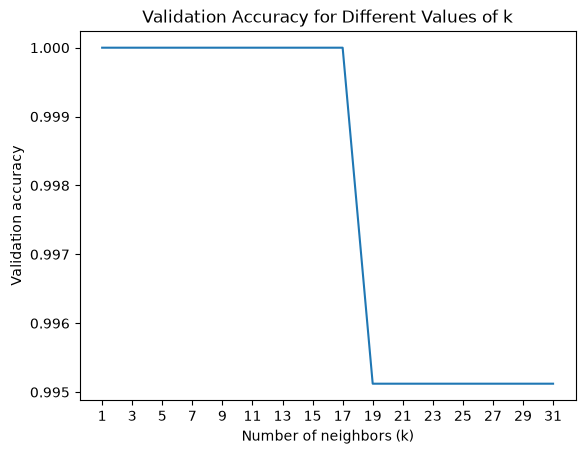

In [25]:
fig, ax = plt.subplots()

ax.plot(k_values, validation_accuracies)

ax.set_xlabel("Number of neighbors (k)")
ax.set_ylabel("Validation accuracy")
ax.set_title("Validation Accuracy for Different Values of k")
ax.set_xticks(k_values)

figures_path = project_root / "figures"

fig.savefig(
    figures_path / "validation_accuracy.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Hyperparameter Selection — Conclusion

The classifier achieves perfect validation accuracy for all tested odd values of `k` from 1 to 17. For larger values, the accuracy decreases slightly to approximately 99.5%.

This indicates that the model is relatively stable across a broad range of neighborhood sizes. We select `k = 7` as the final value because it provides perfect validation performance while using several neighbors rather than relying on a single observation.

In [26]:
best_k = 7

## Final Model Evaluation

After selecting the hyperparameter `k` using the validation set, we evaluate the final classifier on the previously unseen test set.

The test set has not been used during model development or hyperparameter selection, so its performance provides an estimate of how well the classifier generalizes to new observations.

The final model uses:

- standardized features,
- the training set as the reference dataset,
- `k = 7` nearest neighbors.

In [27]:
test_predictions = []

for i in range(len(X_test_scaled)):
    query_point = X_test_scaled.iloc[i].tolist()
    prediction = knn_predict(X_train_scaled, y_train, query_point, best_k)
    test_predictions.append(prediction)

correct_predictions = 0

for i in range(len(test_predictions)):
    if test_predictions[i] == y_test.iloc[i]:
        correct_predictions += 1

test_accuracy = correct_predictions / len(test_predictions)

print(f"Test accuracy: {test_accuracy}")

Test accuracy: 1.0


### Test Set Performance

Using the selected value `k = 7`, the classifier achieves an accuracy of **100%** on the previously unseen test set.

This means that all test observations were classified correctly. The result suggests that the selected features provide strong separation between the two target classes and that the kNN classifier generalizes very well to unseen observations in this dataset.

### Classification Metrics

Accuracy provides an overall measure of classifier performance, but it does not show what types of classification errors were made.

To analyze the predictions in more detail, we calculate the components of the confusion matrix:

- **True Positive (TP)** — class 1 correctly predicted as class 1,
- **True Negative (TN)** — class 0 correctly predicted as class 0,
- **False Positive (FP)** — class 0 incorrectly predicted as class 1,
- **False Negative (FN)** — class 1 incorrectly predicted as class 0.

These values will also be used to calculate precision, recall, and F1-score.

In [28]:
true_positive = 0
true_negative = 0
false_positive = 0
false_negative = 0

for i in range(len(test_predictions)):
    predicted = test_predictions[i]
    actual = y_test.iloc[i]

    if actual == 1 and predicted == 1:
        true_positive += 1
    elif actual == 0 and predicted == 0:
        true_negative += 1
    elif actual == 0 and predicted == 1:
        false_positive += 1
    else:
        false_negative += 1

print("True positives:", true_positive)
print("True negatives:", true_negative)
print("False positives:", false_positive)
print("False negatives:", false_negative)
    

True positives: 92
True negatives: 115
False positives: 0
False negatives: 0


In [29]:
precision = true_positive / (true_positive + false_positive)
recall = true_positive / (true_positive + false_negative)
f1_score = 2 * precision * recall / (precision + recall)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1_score:.4f}")

Test accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-score: 1.0000


### Confusion Matrix

The confusion matrix summarizes the classifier's predictions by comparing predicted and actual classes.

For the final model, all test observations were classified correctly. Therefore, both the false positive and false negative counts are equal to zero.

In [30]:
confusion_matrix = [
    [true_negative, false_positive],
    [false_negative, true_positive]
]

for row in confusion_matrix:
    print(row)

[115, 0]
[0, 92]


### Confusion Matrix Visualization

The confusion matrix is visualized to show how the final classifier performs for each target class.

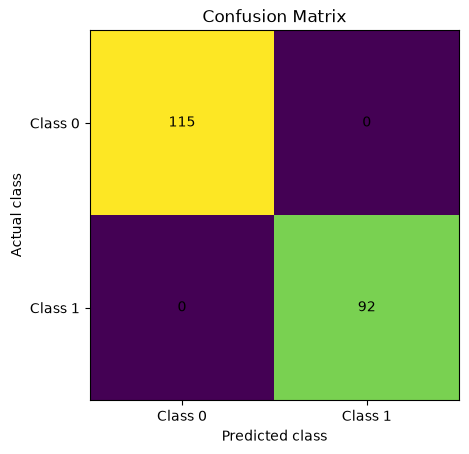

In [31]:
fig, ax = plt.subplots()

image = ax.imshow(confusion_matrix)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Class 0", "Class 1"])
ax.set_yticklabels(["Class 0", "Class 1"])

ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_title("Confusion Matrix")

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            confusion_matrix[i][j],
            ha="center",
            va="center"
        )

plt.show()

figures_path = project_root / "figures"

fig.savefig(
    figures_path / "confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)